# Stage 10 — Threshold Sensitivity and Final Detection Evaluation

This stage uses **only the saved Stage 9 per-sample scores**. It does not rerun Stages 1–9, retrain the model, rebuild the graph, or regenerate attacks.

## Analysis plan
1. Load `Stage9_Outputs.zip`.
2. Sweep candidate thresholds using **validation data only**.
3. Select one common threshold that maximizes the mean F1-score across FGSM, PGD and CW-L2 on validation data.
4. Break ties by preferring the lower mean false-positive rate.
5. Freeze the selected threshold and evaluate it once on the test data.
6. Compare the selected threshold with the Stage 9 95th-percentile clean-validation threshold.
7. Export manuscript-ready tables and plots.

**Important:** Threshold tuning can change the precision/recall trade-off, but it cannot repair poor ranking/separation. If CW-L2 AUC remains below 0.5, changing the threshold cannot make its anomaly scores reliably rank CW-L2 attacks above clean samples. We will report this honestly.


## Step 1 — Upload the Stage 9 output ZIP

Upload the ZIP generated by Stage 9: **`Stage9_Outputs.zip`**.

In [1]:
from google.colab import files
uploaded = files.upload()

import os, zipfile, glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score, roc_auc_score

zips = [x for x in uploaded if x.lower().endswith(".zip")]
if not zips:
    raise FileNotFoundError("Please upload Stage9_Outputs.zip")

extract_dir = "/content/stage10_stage9_inputs"
os.makedirs(extract_dir, exist_ok=True)
with zipfile.ZipFile(zips[0], "r") as zf:
    zf.extractall(extract_dir)

score_files = glob.glob(os.path.join(extract_dir, "**", "stage9_all_sample_scores_and_severity.csv"), recursive=True)
config_files = glob.glob(os.path.join(extract_dir, "**", "stage9_method_config.json"), recursive=True)
if not score_files:
    raise FileNotFoundError("stage9_all_sample_scores_and_severity.csv not found in ZIP")

df = pd.read_csv(score_files[0])
required = {"split","attack","sample_type","true_detection_label","attack_success","anomaly_score"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

df["anomaly_score"] = pd.to_numeric(df["anomaly_score"], errors="coerce")
df["true_detection_label"] = pd.to_numeric(df["true_detection_label"], errors="coerce").astype(int)
df["attack_success"] = df["attack_success"].astype(str).str.lower().isin(["true","1","yes"])
df["split_norm"] = df["split"].astype(str).str.lower()
df["sample_type_norm"] = df["sample_type"].astype(str).str.lower()
df = df.dropna(subset=["anomaly_score"]).copy()

stage9_threshold = None
if config_files:
    with open(config_files[0], "r") as f:
        cfg = json.load(f)
    stage9_threshold = cfg.get("calibrated_threshold")

print("Rows loaded:", len(df))
print("Stage 9 calibrated threshold:", stage9_threshold)
display(df.groupby(["split_norm","attack","sample_type_norm"]).size().rename("n").reset_index())


Saving Stage9_Outputs.zip to Stage9_Outputs.zip
Rows loaded: 35364
Stage 9 calibrated threshold: 3.7890957713127134


,split_norm,attack,sample_type_norm,n
0,test,CW_L2,adversarial,793
1,test,CW_L2,clean_paired,793
2,test,FGSM,adversarial,793
3,test,FGSM,clean_paired,793
4,test,PGD,adversarial,793
5,test,PGD,clean_paired,793
6,train,CW_L2,adversarial,4303
7,train,CW_L2,clean_paired,4303
8,train,FGSM,adversarial,4303
9,train,FGSM,clean_paired,4303


## Step 2 — Build validation and test evaluation sets

For each attack, pair clean samples with successful adversarial samples. The same clean samples may appear in each attack comparison, as in Stage 9. Failed adversarial attempts are excluded from the positive detection class.

In [2]:
ATTACKS = ["FGSM", "PGD", "CW_L2"]

def make_eval_arrays(split_name, attack_name):
    part = df[(df["split_norm"] == split_name) & (df["attack"] == attack_name)]
    clean = part[part["sample_type_norm"] == "clean_paired"]
    adv = part[(part["sample_type_norm"] == "adversarial") & part["attack_success"]]
    if len(clean) == 0 or len(adv) == 0:
        return None
    y = np.concatenate([np.zeros(len(clean), dtype=int), np.ones(len(adv), dtype=int)])
    scores = np.concatenate([clean["anomaly_score"].to_numpy(), adv["anomaly_score"].to_numpy()])
    return y, scores, len(clean), len(adv)

val_data = {a: make_eval_arrays("validation", a) for a in ATTACKS}
test_data = {a: make_eval_arrays("test", a) for a in ATTACKS}
for a in ATTACKS:
    if val_data[a] is None or test_data[a] is None:
        raise ValueError(f"Missing validation or test clean/adversarial pairs for {a}")
print("All three attacks have validation and test evaluation data.")


All three attacks have validation and test evaluation data.


## Step 3 — Sweep thresholds on validation data only

We evaluate candidate cut-offs from the combined validation score distribution. A sample is classified as adversarial when `anomaly_score > threshold`.

Selection rule: maximize the **mean F1-score across the three attacks**. If multiple thresholds have the same mean F1 (to numerical precision), choose the one with the lower mean false-positive rate. The test set is not used to select the threshold.

In [3]:
# Candidate thresholds are midpoints between unique validation scores,
# plus boundary candidates. A maximum of 1,001 quantile-based candidates
# keeps the sweep efficient while covering the score range.
all_val_scores = np.concatenate([val_data[a][1] for a in ATTACKS])
q = np.linspace(0.0, 1.0, 1001)
candidates = np.unique(np.quantile(all_val_scores, q))
candidates = np.unique(np.concatenate([
    [float(all_val_scores.min()) - 1e-9],
    candidates,
    [float(all_val_scores.max()) + 1e-9]
]))

def metrics_at_threshold(y, scores, threshold):
    pred = (scores > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0,1]).ravel()
    return {
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "accuracy": accuracy_score(y, pred),
        "FPR": fp/(fp+tn) if fp+tn else np.nan
    }

sweep_rows=[]
for t in candidates:
    per_attack=[]
    for a in ATTACKS:
        y,s,_,_ = val_data[a]
        m=metrics_at_threshold(y,s,float(t))
        per_attack.append(m)
    sweep_rows.append({
        "threshold": float(t),
        "mean_F1": float(np.mean([m["f1"] for m in per_attack])),
        "mean_precision": float(np.mean([m["precision"] for m in per_attack])),
        "mean_recall": float(np.mean([m["recall"] for m in per_attack])),
        "mean_FPR": float(np.mean([m["FPR"] for m in per_attack]))
    })

sweep_df=pd.DataFrame(sweep_rows)
best_f1=sweep_df["mean_F1"].max()
near_best=sweep_df[np.isclose(sweep_df["mean_F1"], best_f1, rtol=0, atol=1e-12)]
best_row=near_best.sort_values(["mean_FPR","threshold"], ascending=[True,True]).iloc[0]
selected_threshold=float(best_row["threshold"])

print("Selected validation threshold:", selected_threshold)
print("Mean validation F1:", float(best_row["mean_F1"]))
print("Mean validation FPR:", float(best_row["mean_FPR"]))
display(sweep_df.sort_values(["mean_F1","mean_FPR"], ascending=[False,True]).head(15).round(5))


Selected validation threshold: 1.2062930905818938
Mean validation F1: 0.6801393323373294
Mean validation FPR: 0.929406850459482


,threshold,mean_F1,mean_precision,mean_recall,mean_FPR
39,1.20629,0.68014,0.51682,0.99457,0.92941
48,1.22160,0.68000,0.51843,0.98830,0.91771
47,1.22054,0.67990,0.51819,0.98872,0.91896
44,1.21389,0.67988,0.51757,0.99081,0.92314
45,1.21592,0.67979,0.51770,0.98997,0.92189
82,1.26728,0.67978,0.52516,0.96533,0.87260
38,1.20492,0.67975,0.51637,0.99457,0.93108
43,1.21340,0.67968,0.51723,0.99123,0.92481
41,1.20938,0.67967,0.51686,0.99248,0.92732
52,1.23006,0.67963,0.51896,0.98496,0.91270


## Step 4 — Compare validation and test performance

The selected threshold is frozen. No test-driven adjustment is made. The table includes AUC, which is threshold-independent and therefore helps show whether a threshold change can address poor score separation.

In [4]:
result_rows=[]
for split_name, data_dict in [("validation", val_data), ("test", test_data)]:
    for a in ATTACKS:
        y,s,nclean,nadv=data_dict[a]
        m=metrics_at_threshold(y,s,selected_threshold)
        auc=roc_auc_score(y,s)
        result_rows.append({
            "split":split_name, "attack":a, "threshold":selected_threshold,
            "clean_samples":nclean, "successful_adversarial_samples":nadv,
            **m, "AUC":float(auc)
        })
final_metrics=pd.DataFrame(result_rows)
display(final_metrics.round(4))


,split,attack,threshold,clean_samples,successful_adversarial_samples,TN,FP,FN,TP,precision,recall,f1,accuracy,FPR,AUC
0,validation,FGSM,1.2063,798,797,46,752,1,796,0.5142,0.9987,0.6789,0.5279,0.9424,0.8344
1,validation,PGD,1.2063,798,797,37,761,0,797,0.5116,1.0000,0.6769,0.5229,0.9536,0.9855
2,validation,CW_L2,1.2063,798,798,86,712,12,786,0.5247,0.9850,0.6847,0.5464,0.8922,0.4210
3,test,FGSM,1.2063,793,793,45,748,0,793,0.5146,1.0000,0.6795,0.5284,0.9433,0.8414
4,test,PGD,1.2063,793,793,37,756,0,793,0.5119,1.0000,0.6772,0.5233,0.9533,0.9849
5,test,CW_L2,1.2063,793,793,84,709,20,773,0.5216,0.9748,0.6796,0.5404,0.8941,0.4261


## Step 5 — Compare with the Stage 9 threshold and inspect score separation

This comparison shows whether threshold calibration materially changes the operating point. AUC remains unchanged because it depends on score ranking, not the selected cut-off.

,threshold_method,threshold,attack,TN,FP,FN,TP,precision,recall,f1,accuracy,FPR,AUC
0,Stage9_clean_95th_percentile,3.7891,FGSM,754,39,615,178,0.8203,0.2245,0.3525,0.5876,0.0492,0.8414
1,Stage9_clean_95th_percentile,3.7891,PGD,745,48,22,771,0.9414,0.9723,0.9566,0.9559,0.0605,0.9849
2,Stage9_clean_95th_percentile,3.7891,CW_L2,778,15,793,0,0.0000,0.0000,0.0000,0.4905,0.0189,0.4261
3,Stage10_validation_mean_F1,1.2063,FGSM,45,748,0,793,0.5146,1.0000,0.6795,0.5284,0.9433,0.8414
4,Stage10_validation_mean_F1,1.2063,PGD,37,756,0,793,0.5119,1.0000,0.6772,0.5233,0.9533,0.9849
5,Stage10_validation_mean_F1,1.2063,CW_L2,84,709,20,773,0.5216,0.9748,0.6796,0.5404,0.8941,0.4261


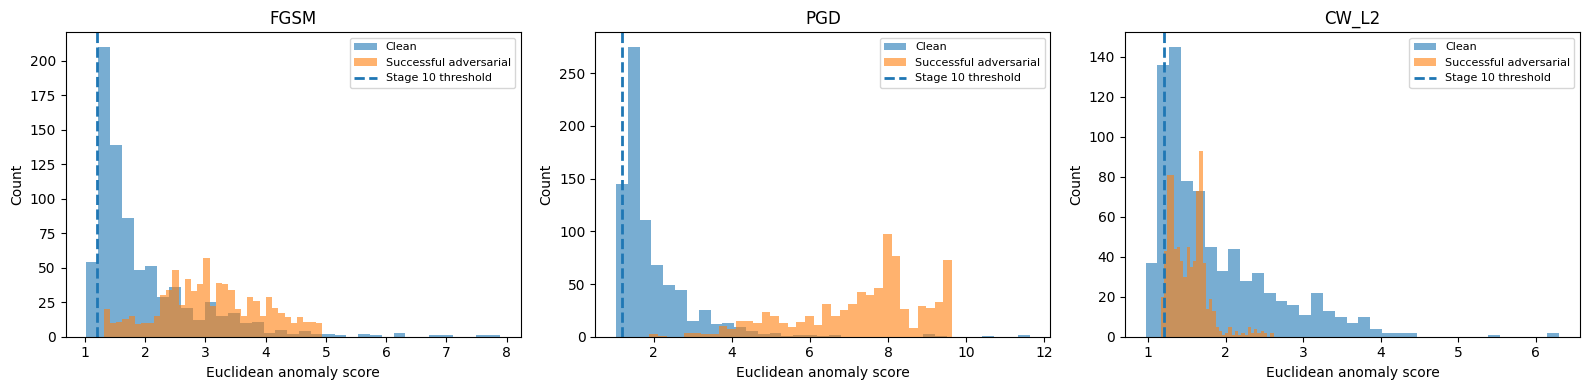

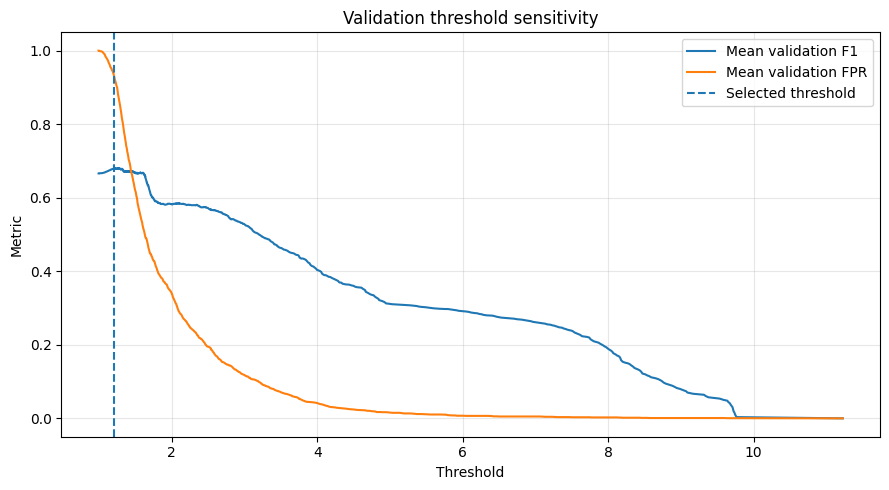

In [5]:
compare_rows=[]
thresholds_to_compare={"Stage9_clean_95th_percentile": stage9_threshold,
                       "Stage10_validation_mean_F1": selected_threshold}
for label,t in thresholds_to_compare.items():
    if t is None:
        continue
    for a in ATTACKS:
        y,s,_,_=test_data[a]
        m=metrics_at_threshold(y,s,float(t))
        compare_rows.append({"threshold_method":label,"threshold":float(t),"attack":a,
                             **m,"AUC":float(roc_auc_score(y,s))})
threshold_comparison=pd.DataFrame(compare_rows)
display(threshold_comparison.round(4))

# Score distribution plot for test set, split by clean/adversarial.
fig, axes=plt.subplots(1,3,figsize=(16,4))
for ax,a in zip(axes,ATTACKS):
    y,s,_,_=test_data[a]
    ax.hist(s[y==0], bins=35, alpha=0.6, label="Clean")
    ax.hist(s[y==1], bins=35, alpha=0.6, label="Successful adversarial")
    ax.axvline(selected_threshold, linestyle="--", linewidth=2, label="Stage 10 threshold")
    ax.set_title(a)
    ax.set_xlabel("Euclidean anomaly score")
    ax.set_ylabel("Count")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Threshold sensitivity curve on validation data.
plt.figure(figsize=(9,5))
plt.plot(sweep_df["threshold"], sweep_df["mean_F1"], label="Mean validation F1")
plt.plot(sweep_df["threshold"], sweep_df["mean_FPR"], label="Mean validation FPR")
plt.axvline(selected_threshold, linestyle="--", label="Selected threshold")
plt.xlabel("Threshold")
plt.ylabel("Metric")
plt.title("Validation threshold sensitivity")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Step 6 — Export Stage 10 results

Download the ZIP and upload it here. It contains the threshold sweep, selected threshold, final validation/test metrics, threshold comparison, and plots.

In [6]:
out_dir="/content/Stage10_Outputs"
os.makedirs(out_dir,exist_ok=True)

sweep_df.to_csv(os.path.join(out_dir,"stage10_validation_threshold_sweep.csv"),index=False)
final_metrics.to_csv(os.path.join(out_dir,"stage10_final_detection_metrics.csv"),index=False)
threshold_comparison.to_csv(os.path.join(out_dir,"stage10_stage9_vs_stage10_threshold_comparison.csv"),index=False)

config_out={
    "input":"Stage9_Outputs.zip",
    "threshold_selection":"Maximize mean validation F1 across FGSM, PGD and CW_L2; tie-break by lower mean validation FPR",
    "selected_threshold":selected_threshold,
    "validation_only_threshold_selection":True,
    "test_set_used_for_threshold_selection":False,
    "decision_rule":"adversarial if Euclidean anomaly_score > selected_threshold",
    "attacks":ATTACKS,
    "warning":"AUC is threshold-independent. Threshold tuning cannot fix poor score ranking/separation, particularly if CW_L2 AUC remains below 0.5."
}
with open(os.path.join(out_dir,"stage10_method_config.json"),"w") as f:
    json.dump(config_out,f,indent=2)

# Save plots as PNG for manuscript review.
for i,a in enumerate(ATTACKS):
    y,s,_,_=test_data[a]
    plt.figure(figsize=(6,4))
    plt.hist(s[y==0],bins=35,alpha=0.6,label="Clean")
    plt.hist(s[y==1],bins=35,alpha=0.6,label="Successful adversarial")
    plt.axvline(selected_threshold,linestyle="--",linewidth=2,label="Selected threshold")
    plt.title(f"Test score distributions — {a}")
    plt.xlabel("Euclidean anomaly score")
    plt.ylabel("Count")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir,f"stage10_test_score_distribution_{a}.png"),dpi=200)
    plt.close()

plt.figure(figsize=(8,5))
plt.plot(sweep_df["threshold"],sweep_df["mean_F1"],label="Mean validation F1")
plt.plot(sweep_df["threshold"],sweep_df["mean_FPR"],label="Mean validation FPR")
plt.axvline(selected_threshold,linestyle="--",label="Selected threshold")
plt.xlabel("Threshold")
plt.ylabel("Metric")
plt.title("Validation threshold sensitivity")
plt.legend()
plt.grid(True,alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(out_dir,"stage10_validation_threshold_sensitivity.png"),dpi=200)
plt.close()

zip_out="/content/Stage10_Outputs.zip"
with zipfile.ZipFile(zip_out,"w",zipfile.ZIP_DEFLATED) as zf:
    for root,_,names in os.walk(out_dir):
        for name in names:
            full=os.path.join(root,name)
            zf.write(full,arcname=os.path.relpath(full,out_dir))
print("Created:",zip_out)
files.download(zip_out)


Created: /content/Stage10_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>